In [1]:
import myhda_ur as hda

In [2]:
hdata = hda.load_scifate()

In [3]:
top_hvg = hdata.get_highly_variable_genes(n=2000)

In [4]:
cells_hvg = hdata.get_timepoint_cells(n=100)

In [5]:
subset_cells_ = hdata[top_hvg, cells_hvg] 

# Cell

## Total RNA

### Expression-distance clusters

gene x cell expression matrix -> distance matrix -> cluster 

In [ ]:
# Cluster the cells using KMeans
hdata.cluster_kmeans(
        data = subset_cells_,
        key = "X",
        kind = "cell",
        k = 6,
        id = "cl1"
    )

cl1 = hdata.clusters["cl1"]

Cluster "cl1" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna']
  similarities: []
  clusters: ['cl1']
  embeddings: []
  trajectories: Yes

In [ ]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data = subset_cells_,
    key = "X",
    kind = "cell",
    id = "em1"
)

em1 = hdata.embeddings["em1"]

UMAP embedding "em1" stored! 



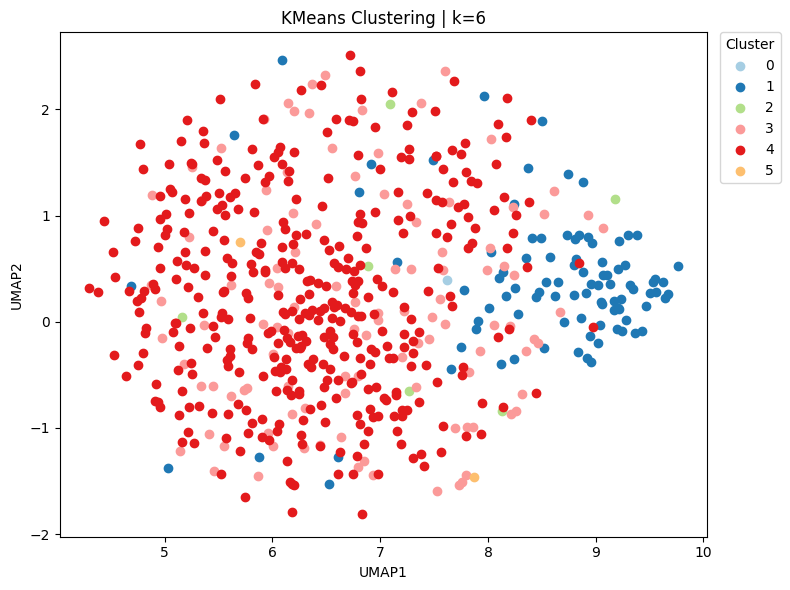

In [ ]:
# Visualize 
hda.visualize.scatter(
    cluster=cl1,
    embedding=em1,
    title="KMeans Clustering | k=6",
    show_label=False
)

In [ ]:
score1 = hdata.calc_cl_silhouette_score(
        cl=cl1, 
        precomputed=False, 
        data = subset_cells_,
        key = "X",
        kind = "cell"
        )

print(f'Silhouette score: {score1:.5f}')

Silhouette score: 0.03081


### PCA-based clusters 

gene x cell expression matrix -> PCA (cell x PC) -> distance matrix -> cluster

In [6]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=20
)

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell']
  similarities: []
  clusters: []
  embeddings: []
  trajectories: Yes

In [7]:
# Cluster in PC space
hdata.cluster_kmeans(
        data = subset_cells_,
        key = "pca_cell",
        kind = "cell",
        k = 6,
        id = "cl2"
    )

cl2 = hdata.clusters["cl2"]

Cluster "cl2" stored! 



In [9]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id="em2"
)

em2 = hdata.embeddings["em2"]

UMAP embedding "em2" stored! 



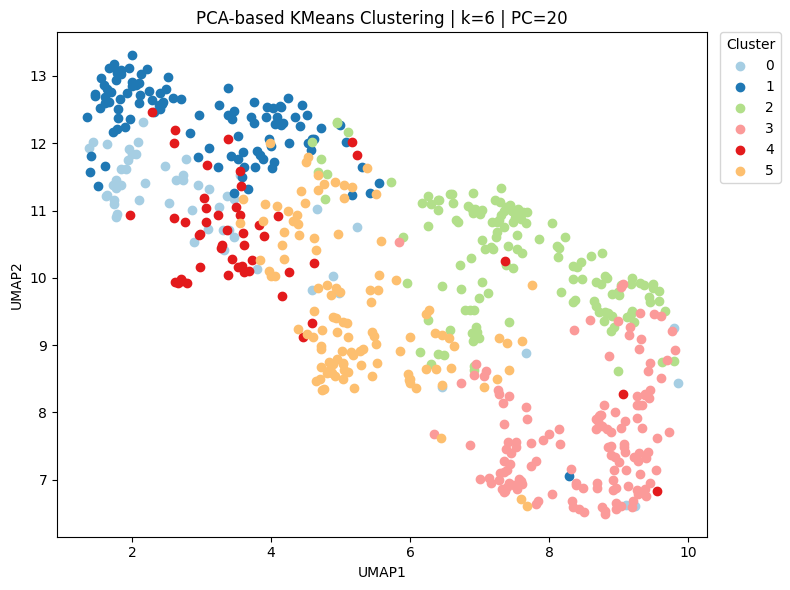

In [10]:
# Visualize 
hda.visualize.scatter(
    cluster=cl2,
    embedding=em2,
    title="PCA-based KMeans Clustering | k=6 | PC=20",
    show_label=False
)

## New RNA

In [12]:
# PCA on new RNA
hdata.compute_PCA(
    data=subset_cells_,
    key="new_rna",      
    kind="cell",
    n_pc=20,
    id="new"
)

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell_new"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell', 'pca_cell_new']
  similarities: []
  clusters: ['cl2']
  embeddings: ['pc20', 'em2']
  trajectories: Yes

In [13]:
# Cluster in PC space
hdata.cluster_kmeans(
        data = subset_cells_,
        key = "pca_cell_new",
        kind = "cell",
        k = 6,
        id = "cl3"
    )

cl3 = hdata.clusters["cl3"]

Cluster "cl3" stored! 



In [14]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell_new",
    kind="cell",
    id="em3"
)

em3 = hdata.embeddings["em3"]

UMAP embedding "em3" stored! 



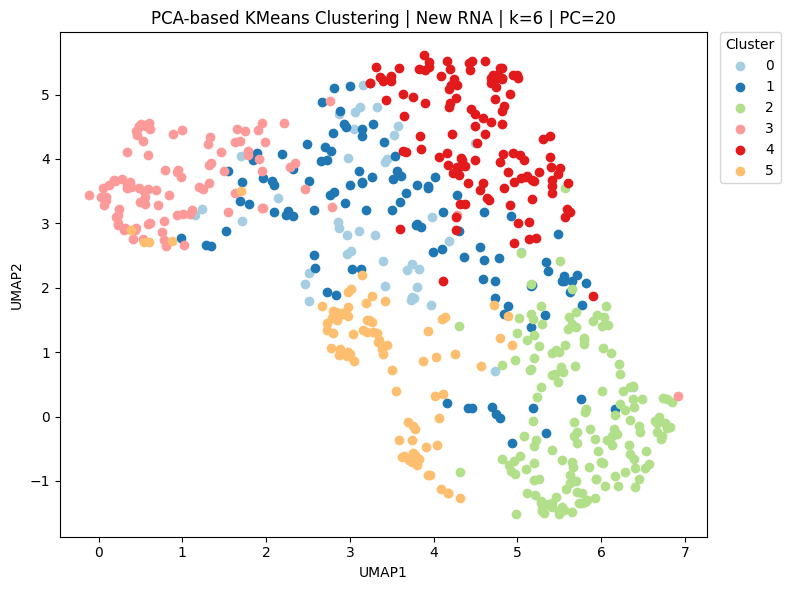

In [15]:
# Visualize 
hda.visualize.scatter(
    cluster=cl3,
    embedding=em3,
    title="PCA-based KMeans Clustering | New RNA | k=6 | PC=20",
    show_label=False
)